# Flight Network Analysis: Comparing Real-World Aviation with Ideal Network Models

Flight networks are one of the most concrete examples of **real-world networks** that exhibit complex properties: heavy-tailed degree distributions,   
efficient global connectivity, and strong geographic community structures.
This analysis constructs a flight network from two open data sources:
 - **OurAirports** (`airports.csv`): global airport metadata — IATA codes, type, location
 - **OpenFlights** (`routes.dat`): flight route data between airports

After building the real network, we compare it with **five ideal network models** using identical N and ⟨k⟩, so that any differences arise   
purely from the network formation mechanisms, not from size or density.

In [1]:
import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
import powerlaw
from scipy import stats

sns.set_style('darkgrid')   
plt.rcParams.update({
    'figure.figsize': (14, 5),
    'axes.titlesize': 15,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
})

---
## 1. Load Raw Data

In [2]:
routes = pd.read_csv('datasets/routes.dat', header=None,
                     names=['airline', 'airline_id', 'src', 'src_id', 'dst','dst_id', 'codeshare', 'stops', 'equipment'],
                     na_values=['\\N'])

airports = pd.read_csv('datasets/airports.csv')

---
## 2. Data Cleaning & EDA

Before building the graph, we need to understand the condition of the raw data:

missing values, duplicates, outliers, and the distribution of important attributes.

In [3]:
# 2a. Routes — early inspection
print('=== ROUTES RAW ===')
print(f'Shape       : {routes.shape}')
print(f'Missing (%) :\n{(routes.isna().mean() * 100).round(2)}')
print(f'Duplicate rows: {routes.duplicated().sum()}')
print()


=== ROUTES RAW ===
Shape       : (67663, 9)
Missing (%) :
airline        0.00
airline_id     0.71
src            0.00
src_id         0.33
dst            0.00
dst_id         0.33
codeshare     78.43
stops          0.00
equipment      0.03
dtype: float64
Duplicate rows: 0



In [4]:
# 2a. airports — early inspection
print('=== AIRPORTS RAW ===')
print(f'Shape       : {airports.shape}')
print(f'Missing (%) :\n{(airports.isna().mean() * 100).round(2)}')
print(f'Airport types:\n{airports["type"].value_counts()}')
print()

=== AIRPORTS RAW ===
Shape       : (85231, 19)
Missing (%) :
id                    0.00
ident                 0.00
type                  0.00
name                  0.00
latitude_deg          0.00
longitude_deg         0.00
elevation_ft         17.31
continent            46.41
iso_country           0.36
iso_region            0.00
municipality          5.52
scheduled_service     0.00
icao_code            88.32
iata_code            89.37
gps_code             48.19
local_code           57.71
home_link            94.50
wikipedia_link       80.42
keywords             75.06
dtype: float64
Airport types:
type
small_airport     42574
heliport          22901
closed            13156
medium_airport     4094
seaplane_base      1260
large_airport      1185
balloonport          61
Name: count, dtype: int64



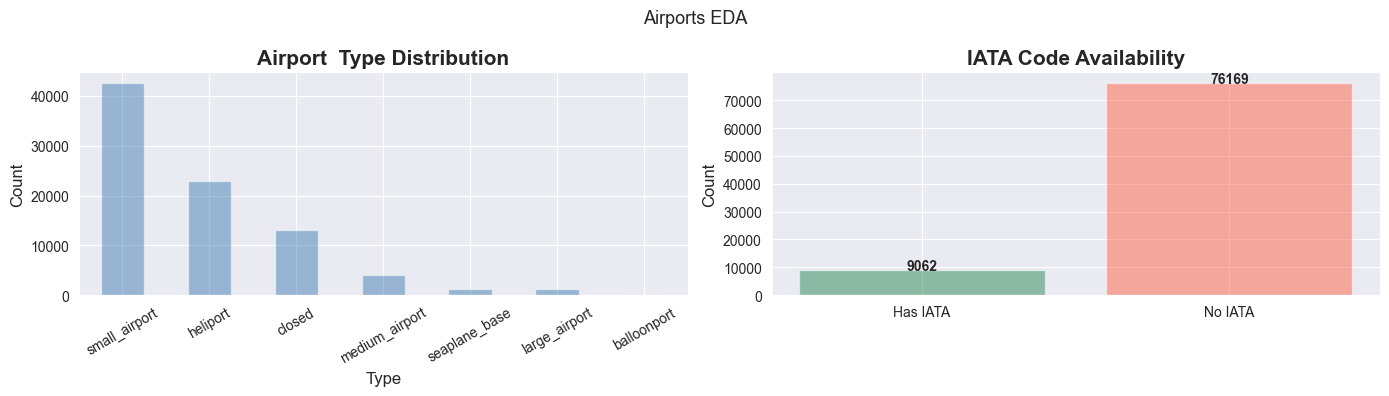

In [5]:
# 2c. Airport type distribution
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

airports['type'].value_counts().plot(kind='bar', ax=axes[0], color='steelblue', alpha=0.5)
axes[0].set_title('Airport  Type Distribution')
axes[0].set_xlabel('Type')
axes[0].set_ylabel('Count')
axes[0].tick_params(axis='x', rotation=30)

iata_null = airports['iata_code'].isna().sum()
iata_valid = airports['iata_code'].notna().sum()
axes[1].bar(['Has IATA', 'No IATA'], [iata_valid, iata_null], 
            color=['seagreen', 'tomato'], alpha=0.5)
axes[1].set_title('IATA Code Availability')
axes[1].set_ylabel('Count')
for i, v in enumerate([iata_valid, iata_null]):
    axes[1].text(i, v + 10, str(v), ha='center', fontweight='bold')

plt.suptitle('Airports EDA', fontsize=13)
plt.tight_layout()
plt.show()

In [6]:
# 2d. Routes — distribution of stops and codeshare flights
print('=== ROUTES EDA ===')
print(f'Codeshare distribution:\n{routes["codeshare"].value_counts(dropna=False)}')
print(f'\nStops distribution:\n{routes["stops"].value_counts(dropna=False)}')
print()

=== ROUTES EDA ===
Codeshare distribution:
codeshare
NaN    53066
Y      14597
Name: count, dtype: int64

Stops distribution:
stops
0    67652
1       11
Name: count, dtype: int64



> Note: we only take direct flights (stops == 0). Codeshares are kept
because they are not true duplicates — different airlines can operate the same route.

In [7]:
# 2e. Are there duplicate routes (src, dst) across airlines?
route_dupes = routes[['src', 'dst']].dropna().duplicated().sum()
print(f'Duplicate (src, dst) pairs (multi-airline): {route_dupes}')
print(f'→ These are dropped when building the graph (undirected, unique edges)')
print()

Duplicate (src, dst) pairs (multi-airline): 30068
→ These are dropped when building the graph (undirected, unique edges)



> This is NOT a bug — duplicates will be dropped when building the graph so that each edge is unique.

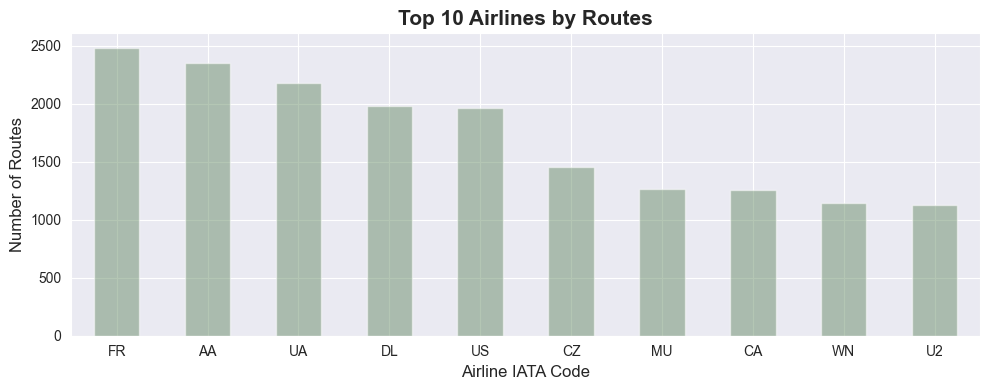

In [8]:
# 2f. Top airlines by number of routes
top_airlines = routes.groupby('airline').size().sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(10, 4))
top_airlines.plot(kind='bar', ax=ax, color='#6B8E6B', alpha=0.5)
ax.set_title('Top 10 Airlines by Routes')
ax.set_xlabel('Airline IATA Code')
ax.set_ylabel('Number of Routes')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

---
## 3. Building the Flight Network

The graph is constructed as an **undirected graph** because flight direction is not relevant
for network structure analysis — routes like CGK→SIN and SIN→CGK represent
the same connection in terms of network accessibility.

### Why only the Giant Connected Component (GCC)?
The original network contains several isolated components — small or regional airports
served only by domestic routes that are not connected to the main international network,
or airports present in the airports database but with no routes in OpenFlights.

The GCC represents the true **backbone of the global flight network**, and
metrics such as average path length are only meaningful within a fully connected component.

The percentage of nodes and edges included in the GCC is an indicator of how *connected*
the network is — values above 95% suggest that the global flight network is essentially
a single highly connected system, rather than a collection of isolated islands.

In [9]:
valid_iata = set(airports[airports['iata_code'].notna()]['iata_code'])

In [10]:
edges = routes[routes['src'].isin(valid_iata) & routes['dst'].isin(valid_iata)]
edges = edges[['src', 'dst']].dropna().drop_duplicates()

In [11]:
G_full = nx.from_pandas_edgelist(edges, source='src', target='dst')
gcc_nodes = max(nx.connected_components(G_full), key=len)
G = G_full.subgraph(gcc_nodes).copy()

In [12]:
# Basic graph stats
print('=== GRAPH CONSTRUCTION ===')
print(f'Full graph — Nodes: {G_full.number_of_nodes()}, Edges: {G_full.number_of_edges()}')
print(f'GCC — Nodes: {G.number_of_nodes()}, Edges: {G.number_of_edges()}')
pct_nodes = G.number_of_nodes() / G_full.number_of_nodes() * 100
pct_edges = G.number_of_edges() / G_full.number_of_edges() * 100
print(f'GCC retains {pct_nodes:.1f}% of nodes, {pct_edges:.1f}% of edges')


=== GRAPH CONSTRUCTION ===
Full graph — Nodes: 3390, Edges: 18835
GCC — Nodes: 3362, Edges: 18809
GCC retains 99.2% of nodes, 99.9% of edges


---
## 4. Graph EDA — Basic Network Structure

After the graph is built, we need to understand its structural characteristics before
comparing it with models. This is not just a sanity check — the findings here will
determine how we interpret the model comparison results.

### Self-loops and Isolates
Self-loops (airports with routes to themselves) are data artifacts, not real phenomena,
and must be removed. Isolates should not exist in the GCC — their presence indicates
a bug in graph construction.

### Degree Distribution
Plotting the degree distribution in both linear and log-log scales provides an initial
understanding of the network type:
- **Linear scale**: is the distribution symmetric (like ER/WS) or highly skewed?
- **Log-log scale**: is there a linear pattern (indicating a power-law / heavy tail)?

Flight networks are expected to exhibit a **heavy tail** — most airports have only a few routes,
while major hubs (ATL, DXB, LHR) have hundreds of connections.
This is a signature of structural heterogeneity that we would not observe in ER graphs.

### Hub Airport Verification
Manually verifying that real-world hubs (Atlanta, Dubai, London Heathrow) appear
in the graph with high degree is a quick way to validate that the data was loaded
correctly and that filtering did not remove important nodes.

### Country Distribution
Country distribution reflects **geographical inequality** in the global flight network —
the US, Europe, and East Asia dominate, while Africa and Oceania are underrepresented.
This is not noise: this imbalance will influence the community structure observed
later in the LFR analysis.

In [13]:
# 4a. Sanity check
# Check for self-loops (airport routing to itself)
self_loops = list(nx.selfloop_edges(G))
print(f'Self-loops: {len(self_loops)}')
G.remove_edges_from(self_loops)

# Any isolated nodes that slipped through?
isolates = list(nx.isolates(G))
print(f'Isolate: {len(isolates)}')

# Check degree distribution for suspicious outliers
degrees = sorted([d for _, d in G.degree()], reverse=True)
print(f'Degree range: min={min(degrees)}, max={max(degrees)}')
print(f'Top 5 degrees: {degrees[:5]}')
print()

Self-loops: 1
Isolate: 0
Degree range: min=1, max=246
Top 5 degrees: [246, 241, 239, 229, 217]



In [14]:
# 4b. Attach node metadata
airport_meta = airports[airports['iata_code'].isin(G.nodes())].set_index('iata_code')

for iata, row in airport_meta.iterrows():
    if iata in G.nodes:
        G.nodes[iata]['country'] = row.get('iso_country', 'Unknown')
        G.nodes[iata]['type'] = row.get('type', 'Unknown')
        G.nodes[iata]['lat'] = row.get('latitude_deg', None)
        G.nodes[iata]['lon'] = row.get('longitude_deg', None)
        G.nodes[iata]['name'] = row.get('name', iata)

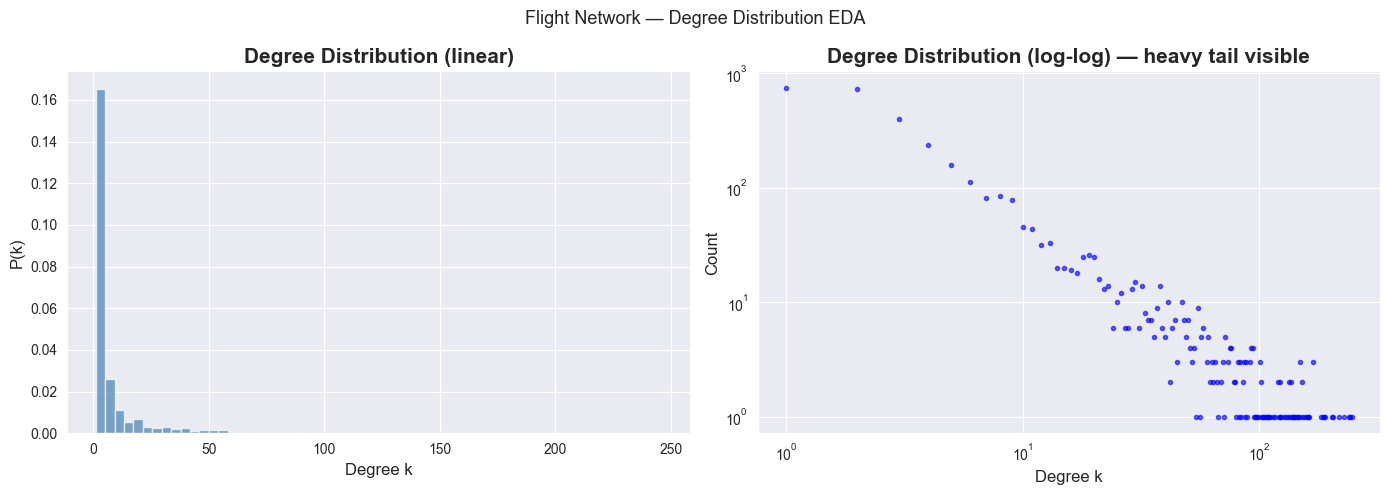

In [15]:
# 4c. Degree distribution plot
deg_values = [d for _, d in G.degree()]
deg_counts = np.bincount(deg_values)
mask = deg_counts > 0
x, y = np.arange(len(deg_counts))[mask], deg_counts[mask]
 
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
 
axes[0].hist(deg_values, bins=60, density=True, color='steelblue', alpha=0.7)
axes[0].set_xlabel('Degree k')
axes[0].set_ylabel('P(k)')
axes[0].set_title('Degree Distribution (linear)')
 
axes[1].loglog(x, y, 'b.', alpha=0.6)
axes[1].set_xlabel('Degree k')
axes[1].set_ylabel('Count')
axes[1].set_title('Degree Distribution (log-log) — heavy tail visible')
 
plt.suptitle('Flight Network — Degree Distribution EDA', fontsize=13)
plt.tight_layout()
plt.show()


In [16]:
# 4d. Known hub airports verification
print('=== HUB AIRPORTS ===')
hubs = ['ATL', 'DXB', 'LHR', 'SIN', 'CDG', 'FRA']
for hub in hubs:
    if hub in G:
        print(f'{hub}: degree {G.degree(hub)}')
    else:
        print(f'{hub}: NOT IN GRAPH ⚠️')

=== HUB AIRPORTS ===
ATL: degree 217
DXB: degree 186
LHR: degree 169
SIN: degree 124
CDG: degree 239
FRA: degree 241


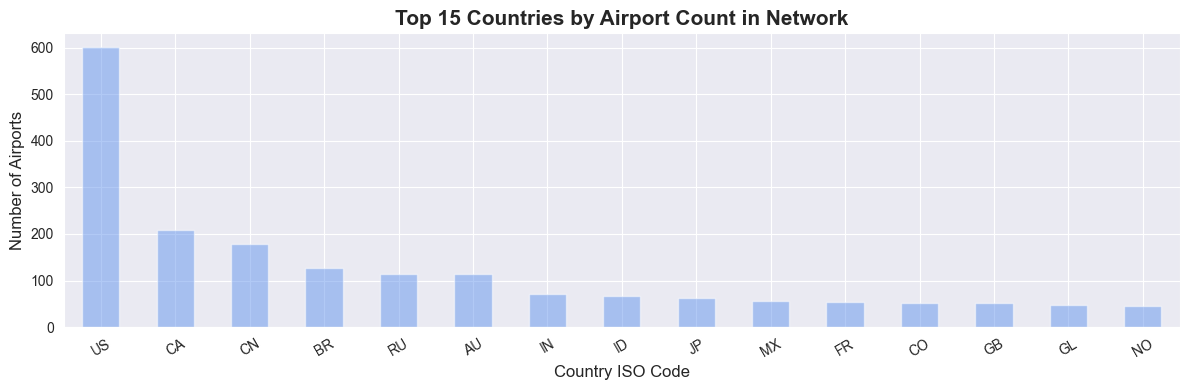

In [17]:
# 4e. Country distribution of airports in network
country_counts = pd.Series(nx.get_node_attributes(G, 'country')).value_counts().head(15)
fig, ax = plt.subplots(figsize=(12, 4))
country_counts.plot(kind='bar', ax=ax, color='cornflowerblue', alpha=0.5)
ax.set_title('Top 15 Countries by Airport Count in Network')
ax.set_xlabel('Country ISO Code')
ax.set_ylabel('Number of Airports')
ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

In [18]:
# 4f, Density and connectivity
print('=== NETWORK SUMMARY ===')
print(f'Nodes       : {G.number_of_nodes()}')
print(f'Edges       : {G.number_of_edges()}')
print(f'Avg degree  : {np.mean(deg_values):.4f}')
print(f'Std degree  : {np.std(deg_values):.4f}')
print(f'Density     : {nx.density(G):.6f}')
print()

=== NETWORK SUMMARY ===
Nodes       : 3362
Edges       : 18808
Avg degree  : 11.1886
Std degree  : 24.2458
Density     : 0.003329



---
## 5. Computing Metrics of the Real Network

Before comparing with models, we first compute all metrics
from the real network as a **baseline**. Each metric is chosen based on its relevance
to the models being compared:

| Metric | Relevance |
|---|---|
| Degree distribution (std) | Comparison with ER, which produces a Poisson distribution |
| Clustering coefficient C | Comparison with WS, which controls C via rewiring |
| Average path length L | Comparison with WS — high C + low L = small-world |
| Power-law exponent α | Comparison with BA, which theoretically yields α ≈ 3 |
| Assortativity r | Comparison with XBS, which controls r via preferential attachment |
| Modularity Q | Comparison with LFR, which embeds community structure |

### Notes on Average Path Length
APL is computed exactly by summing all shortest paths, not via sampling.
This is computationally expensive on large graphs (O(N·E) with BFS),
but provides precise values for comparison with models.

### Notes on Power-law Fit
We use the `powerlaw` library, which implements the Clauset et al. (2009) method —
a maximum likelihood approach that is more robust than simple log-log regression.

Comparison with lognormal is done using a likelihood ratio test (R, p):
- R < 0 → lognormal is a better fit  
- R > 0 → power-law is a better fit  

The finding that the real network fits a **lognormal** distribution better is a substantive result
that we will revisit in the BA and LFR sections.

In [19]:
N = G.number_of_nodes()
avg_k = np.mean(deg_values)
real_deg = np.array(deg_values)

cc = nx.average_clustering(G)
print(f'Clustering coefficient  : {cc:.4f}')

total_lengths = 0
for node in G.nodes():
    path_lengths = nx.single_source_shortest_path_length(G, node)
    total_lengths += sum(v for v in path_lengths.values() if v > 0)


apl = total_lengths / (N * (N - 1))
print(f'Average path length    : {apl:.4f}')

fit = powerlaw.Fit(degrees, discrete=True, verbose=False)

R, p = fit.distribution_compare('power_law', 'lognormal')
print(f'Power law alpha        : {fit.power_law.alpha:.4f}')
print(f'Power law vs Lognormal : R={R:.4f}, p={p:.4f}')
print(f'  → {"Lognormal" if R < 0 else "Power law"} fits better')
print()

assortativity = nx.degree_assortativity_coefficient(G)
print(f'Degree assortativity: {assortativity:.4f}')

communities = nx.community.louvain_communities(G, seed=42)
modularity = nx.community.modularity(G, communities)
print(f'Number of communities: {len(communities)}')
print(f'Modularity: {modularity:.4f}')
print()

Clustering coefficient  : 0.4874
Average path length    : 4.1009
Power law alpha        : 1.7387
Power law vs Lognormal : R=-41.4585, p=0.0000
  → Lognormal fits better

Degree assortativity: -0.0098
Number of communities: 19
Modularity: 0.6682



---
## 6. Model Parameters

All models are constructed with **identical N and ⟨k⟩** as the real network.
This is a requirement for a fair (controlled) comparison — we want differences
in metrics to reflect differences in **formation mechanisms**, not differences
in network size or density.

Parameters used:
- `p_er`: edge probability in ER = ⟨k⟩ / (N-1), chosen so that E[degree] = ⟨k⟩  
- `m_ba`: number of edges added per new node in BA = ⌊⟨k⟩/2⌋,  
           since each new node contributes 2m to the total degree count  
- `k_ws`: initial degree of the ring lattice in WS, rounded to the nearest even number  
- `beta_ws`: rewiring probability = 0.1, chosen in the small-world regime  
             (not too random like β=1, not too regular like β=0)  

The choice of β=0.1 for WS is not arbitrary — within the range β ∈ [0.01, 0.1],
the WS model consistently produces small-world networks with C ≈ C_lattice
and L ≈ L_random. This is the most relevant regime for comparison
with real-world networks.

In [20]:
p_er = avg_k / (N - 1)
m_ba = max(1, int(avg_k / 2))
k_ws = round(avg_k / 2) * 2
beta_ws = 0.1

print(f'N={N}, avg_k={avg_k:.2f}')
print(f'p_er={p_er:.6f}  |  m_ba={m_ba}  |  k_ws={k_ws}, beta={beta_ws}')
print()

N=3362, avg_k=11.19
p_er=0.003329  |  m_ba=5  |  k_ws=12, beta=0.1



---
## 7. Erdős–Rényi — Degree Distribution Comparison

The ER model is the simplest theoretical baseline: each pair of nodes
is connected independently with probability p. The result is a **Binomial degree
distribution**, which for sparse graphs (large N, small p) approaches a **Poisson**
distribution with mean ⟨k⟩.

### Why do we expect ER to fail?
Real-world networks almost always exhibit **degree heterogeneity** far greater
than Poisson — there are hubs with hundreds of connections that would almost
never arise naturally in an ER graph with the same ⟨k⟩. In an ER graph with
⟨k⟩ ≈ 11, the probability of nodes having degree > 50 is zero under Poisson,
whereas in real networks this is quite common.

### Interpretation of the KS Test
The Kolmogorov–Smirnov test measures the maximum distance between two empirical CDFs:
- **D close to 0**: distributions are very similar  
- **D close to 1**: distributions are very different  
- **p < 0.05**: difference is statistically significant  

In addition to the KS statistic, the **standard deviation of degrees** is an intuitive
visual comparator: ER produces std ≈ √⟨k⟩ (narrow), while real networks
have much larger std due to the presence of hubs — this is immediately visible
from the width of the histogram.

A log-log CCDF plot is the best way to visualize this difference:
ER decays rapidly (exponential Poisson tail), whereas real networks
have a much longer tail.

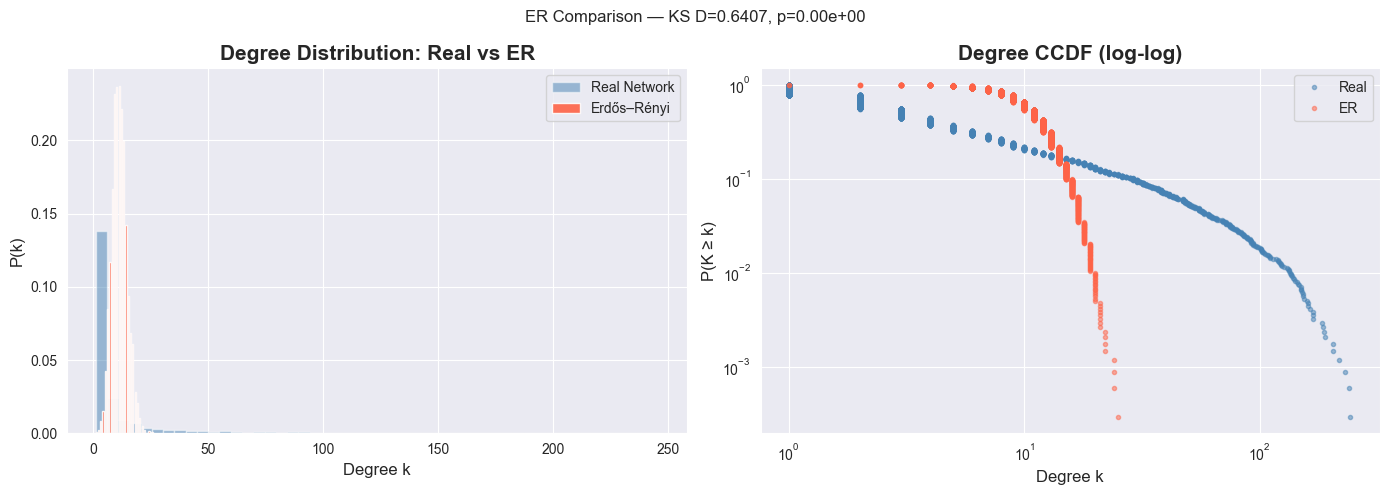

Real  — avg degree: 11.1886, std: 24.2458
ER    — avg degree: 11.0720, std: 3.3441
KS test: D=0.6407, p=0.00e+00
→ Significantly different



In [21]:
ER = nx.erdos_renyi_graph(n=N, p=p_er, seed=42)

real_deg = np.array([d for _, d in G.degree()])
er_deg = np.array([d for _, d in ER.degree()])

ks_stat, ks_p = stats.ks_2samp(real_deg, er_deg)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(real_deg, bins=50, density=True, alpha=0.5, color='steelblue', label='Real Network')
axes[0].hist(er_deg, bins=50, density=True, alpha=0.9, color='tomato', label='Erdős–Rényi')
axes[0].set_xlabel('Degree k')
axes[0].set_ylabel('P(k)')
axes[0].set_title('Degree Distribution: Real vs ER')
axes[0].legend()

for arr, label, color in [(real_deg, 'Real', 'steelblue'), (er_deg, 'ER', 'tomato')]:
    sorted_d = np.sort(arr)
    ccdf = 1 - np.arange(1, len(sorted_d) + 1) / len(sorted_d)
    axes[1].loglog(sorted_d, ccdf, '.', alpha=0.5, label=label, color=color)
axes[1].set_xlabel('Degree k')
axes[1].set_ylabel('P(K ≥ k)')
axes[1].set_title('Degree CCDF (log-log)')
axes[1].legend()

plt.suptitle(f'ER Comparison — KS D={ks_stat:.4f}, p={ks_p:.2e}', fontsize=12)
plt.tight_layout()
plt.show()


print(f'Real  — avg degree: {real_deg.mean():.4f}, std: {real_deg.std():.4f}')
print(f'ER    — avg degree: {er_deg.mean():.4f}, std: {er_deg.std():.4f}')
print(f'KS test: D={ks_stat:.4f}, p={ks_p:.2e}')
print(f'→ {"Significantly different" if ks_p < 0.05 else "No significant difference"}')
print()


---
## 8. Watts–Strogatz — Clustering Coefficient & Average Path Length

The WS model addresses a key question: how can a network simultaneously
have **high C** (like clustered social networks) and **low L**
(like the "six degrees of separation" phenomenon)?

The answer: start from a regular ring lattice (high C, high L), then
randomly rewire a small fraction of edges (small β). This rewiring drastically
reduces L (creating "shortcuts" across clusters) without significantly reducing C.

### Small-World Property
A network is considered small-world if:
- C_real >> C_random  (clustering much higher than a random ER graph)  
- L_real ≈ L_random   (path length comparable to a random graph)  

Ratios C_real/C_ws and L_real/L_ws close to 1 indicate that
WS is a good model for this network. If L_real < L_ws, it suggests that
the real network has an even **stronger small-world property** than WS predicts —
likely because major hub airports act as highly efficient global shortcuts,
beyond what random rewiring produces.

### Aviation Context
In the context of aviation, high C makes sense: airports within the same
region (e.g., Western Europe) tend to be interconnected, forming local clusters.
Low L reflects the fact that with one or two layovers, nearly all major airports
in the world can be reached from anywhere — this is a fundamental efficiency
of the hub-and-spoke aviation design.

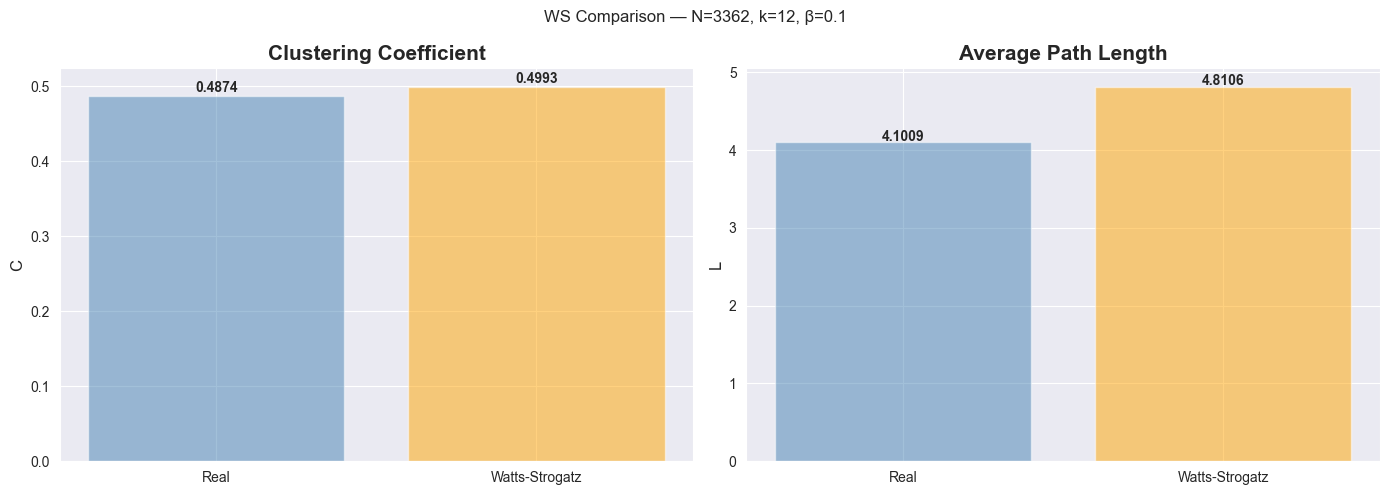

Metric                          Real         WS   Ratio (R/WS)
------------------------------------------------------------
Clustering coeff              0.4874     0.4993         0.9763
Avg path length               4.1009     4.8106         0.8525



In [22]:
WS = nx.watts_strogatz_graph(n=N, k=k_ws, p=beta_ws, seed=42)

ws_cc = nx.average_clustering(WS)
ws_deg = np.array([d for _, d in WS.degree()])

ws_total = sum(
    sum(v for v in nx.single_source_shortest_path_length(WS, node).values() if v > 0)
    for node in WS.nodes()
)
ws_apl = ws_total / (N * (N - 1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

categories = ['Real', 'Watts-Strogatz']
cc_vals = [cc, ws_cc]
apl_vals = [apl, ws_apl]

axes[0].bar(categories, cc_vals, color=['steelblue', 'orange'], alpha=0.5)
axes[0].set_title('Clustering Coefficient')
axes[0].set_ylabel('C')
for i, v in enumerate(cc_vals):
    axes[0].text(i, v + 0.005, f'{v:.4f}', ha='center', fontweight='bold')

axes[1].bar(categories, apl_vals, color=['steelblue', 'orange'], alpha=0.5)
axes[1].set_title('Average Path Length')
axes[1].set_ylabel('L')
for i, v in enumerate(apl_vals):
    axes[1].text(i, v + 0.02, f'{v:.4f}', ha='center', fontweight='bold')

plt.suptitle(f'WS Comparison — N={N}, k={k_ws}, β={beta_ws}', fontsize=12)
plt.tight_layout()
plt.show()
 
print(f'{"Metric":<25} {"Real":>10} {"WS":>10} {"Ratio (R/WS)":>14}')
print('-' * 60)
print(f'{"Clustering coeff":<25} {cc:>10.4f} {ws_cc:>10.4f} {cc/ws_cc:>14.4f}')
print(f'{"Avg path length":<25} {apl:>10.4f} {ws_apl:>10.4f} {apl/ws_apl:>14.4f}')
print()

---
## 9. Barabási–Albert — Scaling Exponent

The BA model introduces the mechanism of **preferential attachment**: new nodes
are more likely to connect to nodes that already have many connections ("rich get richer").
This mechanism produces a power-law degree distribution P(k) ~ k^{-α} with a theoretical α ≈ 3.

### Why does a power-law emerge in flight networks?
Intuitively, large airports attract more new routes because:
- Airlines prefer already busy hubs (more profitable)  
- Passengers prefer routes with better connectivity  

This is a direct analogue of preferential attachment.

### Lognormal Finding — Implications
Distribution comparison results show that the real network **fits a lognormal**
distribution better than a power-law (R < 0, p ≈ 0). This has important implications:

- **Not pure BA**: the formation mechanism of flight networks is not purely
  preferential attachment. Aviation regulations, airport capacity limits,
  geographic constraints, and airline competition impose upper bounds on hub growth
  (degree cutoff), which do not exist in the ideal BA model.  

- **Lognormal is more realistic**: a lognormal distribution arises when growth is
  multiplicative but constrained (multiplicative growth with constraints),
  which better reflects the realities of the aviation industry.  

Comparing α (1.74 vs ~2.88) is still useful as it shows how far the real network
deviates from BA predictions — this significant difference, combined with the
lognormal finding, provides strong evidence that **BA is not an appropriate model**
for flight networks.

NOTE: Real network fits lognormal better than power-law (R=-41.46, p=0.0000).
The alpha comparison should be interpreted cautiously.



c:\one one\Desktop\network-sciences\.venv\Lib\site-packages\powerlaw\distributions.py:743: OptimizeWarning: Initial guess is not within the specified bounds
  result = scipy.optimize.minimize(fit_function,


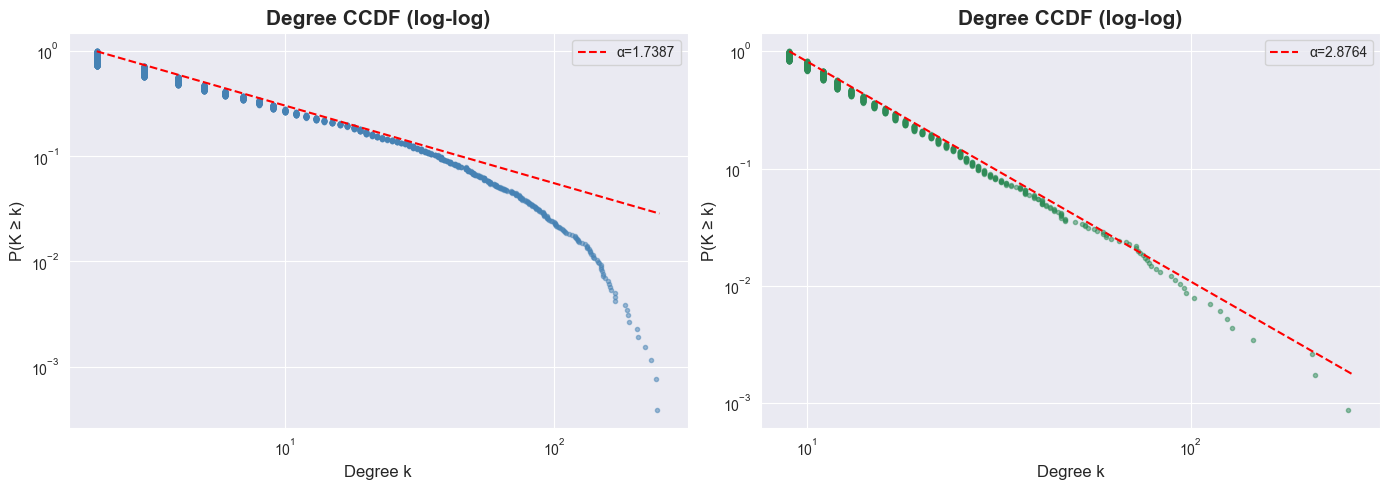

Metric                          Real         BA
----------------------------------------------
Power-law alpha               1.7387     2.8764
xmin                             2.0        9.0



In [23]:
BA = nx.barabasi_albert_graph(n=N, m=m_ba, seed=42)

ba_deg = np.array([d for _, d in BA.degree()])
ba_fit = powerlaw.Fit(ba_deg, discrete=True, verbose=False)
real_fit = fit

print(f'NOTE: Real network fits lognormal better than power-law '
      f'(R={R:.2f}, p={p:.4f}).')
print(f'The alpha comparison should be interpreted cautiously.\n')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, arr, model_fit, title, color in [
    (axes[0], real_deg, real_fit, 'Real Network', 'steelblue'),
    (axes[1], ba_deg, ba_fit, 'Barabási-Albert', 'seagreen'),
]:
    sorted_d = np.sort(arr[arr >= model_fit.power_law.xmin])
    ccdf = 1 - np.arange(1, len(sorted_d) + 1) / len(sorted_d)
    ax.loglog(sorted_d, ccdf, '.', alpha=0.5, color=color)

    x = np.linspace(sorted_d.min(), sorted_d.max(), 200)
    alpha = model_fit.power_law.alpha
    xmin = model_fit.power_law.xmin
    C = xmin ** (alpha - 1)
    
    ax.loglog(x, C * x ** (-(alpha - 1)), 'r--', label=f'α={alpha:.4f}')
    ax.set_xlabel('Degree k')
    ax.set_ylabel('P(K ≥ k)')
    ax.set_title('Degree CCDF (log-log)')
    ax.legend()

plt.tight_layout()
plt.show()

print(f'{"Metric":<25} {"Real":>10} {"BA":>10}')
print('-' * 46)
print(f'{"Power-law alpha":<25} {real_fit.power_law.alpha:>10.4f} {ba_fit.power_law.alpha:>10.4f}')
print(f'{"xmin":<25} {real_fit.power_law.xmin:>10.1f} {ba_fit.power_law.xmin:>10.1f}')
print()

---
## 10. Xulvi-Brunet-Sokolov — Assortativity

**Assortativity** measures the tendency of nodes to connect to others with
similar degree (r > 0, assortative) or different degree (r < 0, disassortative):
- Social networks tend to be **assortative**: people interact with others
  who have similar social circles  
- Biological and technological networks tend to be **disassortative**: hubs connect
  to many small nodes (like large servers serving many small clients)  

### Position of Flight Networks
An r ≈ 0 value (neutral or slightly disassortative) in flight networks
makes sense: large hubs (ATL, DXB) connect to smaller airports,
but also connect to other hubs — not as assortative as social networks,
and not as disassortative as the Internet.

### Implementation Notes (two levels of approximation)
**Level 1 — Generation vs Rewiring:** The original XBS model (Xulvi-Brunet & Sokolov, 2004)
is a *network generation* algorithm based on biased preferential attachment,
not rewiring. We use rewiring because we want to compare assortativity while
preserving the same degree sequence as BA, isolating assortativity as the variable.

**Level 2 — Probabilistic vs Greedy:** The original model uses a probability p
to control assortative/disassortative bias at each step.
Our implementation uses greedy best-swap — always selecting the most
(assortative/disassortative) improving swap. This is more deterministic and
converges faster, but loses the stochastic nature of the original model.

Both approximations are justified because the **comparison metric is the
assortativity coefficient r**, not the generative mechanism.
Greedy rewiring on a BA graph produces controlled r values with a comparable
degree sequence — an ideal condition for isolated comparison.

In [24]:
def xulvi_brunet_sokolov(G_source, target_r, n_swaps:None, seed=42):
    """
    Approximate XBS: degree-based double-edge swaps to push assortativity
    toward target_r.

    Return a new graph.
    """
    rng = np.random.default_rng(seed)
    H = G_source.copy()
    if n_swaps is None:
        n_swaps = H.number_of_edges() * 10
    
    edges = list(H.edges())

    for _ in range(n_swaps):
        if len(edges) < 2:
            break

        if i % 500 == 0:
            current_r = nx.degree_assortativity_coefficient(H)
            if abs(current_r - target_r) < 1e3:
                break
        
        idx = rng.choice(len(edges), size=2, replace=False)
        (u, v), (s, t) = edges[idx[0]], edges[idx[1]]

        if len({u, v, s, t}) < 4:
            continue

        du, dv = H.degree(u), H.degree(v)
        ds, dt = H.degree(s), H.degree(t)

        score_a = abs(du - ds) + abs(dv - dt)
        score_b = abs(du - dt) + abs(dv - ds)

        if target_r > 0:
            swap_to_a = score_a <= score_b
        else:
            swap_to_a = score_a >= score_b
        
        new_u_nb, new_v_nb = (s, t) if swap_to_a else (t, s)

        if not H.has_edge(u, new_u_nb) and not H.has_edge(v, new_v_nb):
            H.remove_edge(u, v)
            H.remove_edge(s, t)
            H.add_edge(u, new_u_nb)
            H.add_edge(v, new_v_nb)
            edges[idx[0]] = (u, new_u_nb)
            edges[idx[1]] = (v, new_v_nb)

    return H

def avg_neighbour_degree_by_k(Gx):
    """Return (degrees, avg_neighbour_degree) sorted by degree."""
    knn = nx.average_neighbor_degree(Gx)
    deg = dict(Gx.degree())
    data = [(deg[n], knn[n]) for n in Gx.nodes()]
    df = pd.DataFrame(data, columns=['k', 'knn']).groupby('k')['knn'].mean().reset_index()
    return df['k'].values, df['knn'].values

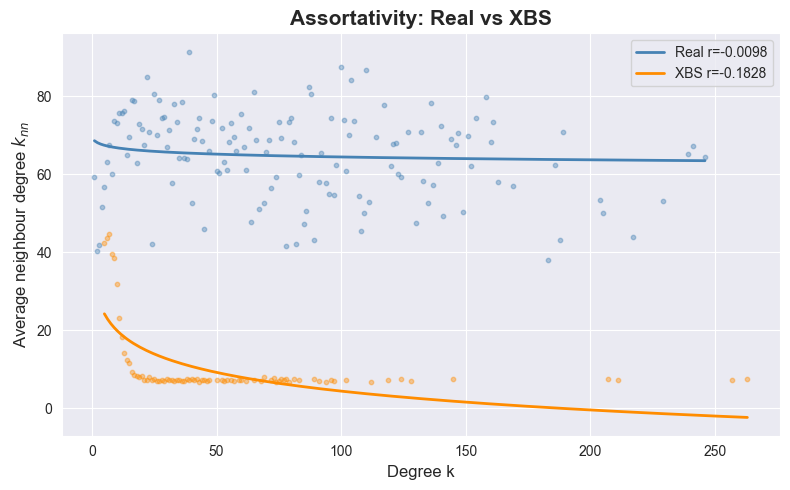

Metric                               Real        XBS
----------------------------------------------------
Degree assortativity r            -0.0098    -0.1828



In [25]:
XBS = xulvi_brunet_sokolov(BA, target_r=assortativity, n_swaps=BA.number_of_edges() * 5, seed=42)

xbs_r = nx.degree_assortativity_coefficient(XBS)
real_r = assortativity

fig, ax = plt.subplots(figsize=(8, 5))
for Gx, label, color in [(G, 'Real', 'steelblue'),
                         (XBS, 'XBS', 'darkorange')]:
    ks, knns = avg_neighbour_degree_by_k(Gx)
    ax.scatter(ks, knns, alpha=0.4, s=10, color=color)

    z = np.polyfit(np.log1p(ks), knns, 1)
    xfit = np.linspace(ks.min(), ks.max(), 200)
    ax.plot(xfit, np.poly1d(z)(np.log1p(xfit)), color=color, linewidth=2, 
            label=f'{label} r={nx.degree_assortativity_coefficient(Gx):.4f}')
ax.set_xlabel('Degree k')
ax.set_ylabel('Average neighbour degree $k_{nn}$')
ax.set_title('Assortativity: Real vs XBS')
ax.legend()
plt.tight_layout()
plt.show()


print(f'{"Metric":<30} {"Real":>10} {"XBS":>10}')
print('-' * 52)
print(f'{"Degree assortativity r":<30} {real_r:>10.4f} {xbs_r:>10.4f}')
print()


---
## 11. LFR Benchmark — Modularity

The LFR model (Lancichinetti, Fortunato & Radicchi, 2008) is the *gold standard*
for testing community detection algorithms. Unlike other models that focus on
degree distribution or global topology, LFR explicitly embeds **community structure**
with controllable characteristics.

### Key Parameters
- **tau1**: exponent of the power-law degree distribution. The real network has
  α = 1.74, but LFR requires τ₁ > 2. We clamp it to 2.5 as the closest approximation.  
  *Note: the real network is actually better modeled by a lognormal distribution,
  so LFR does not truly replicate the real degree distribution — this is a limitation
  that should be acknowledged.*  

- **tau2**: exponent of the community size distribution. τ₂ = 1.5 produces
  realistic variation in community sizes (a few large, many small)  

- **mu**: mixing parameter — the proportion of edges connecting nodes
  from different communities. μ = 0.3 means 70% of edges are within communities
  (a fairly strong community structure)  

### Interpreting Modularity Q
Modularity Q ∈ [-1, 1] measures how well a network is partitioned into communities:
- Q > 0.3: meaningful community structure  
- Q > 0.5: strong community structure  
- Q → 1: communities are highly isolated from each other  

If Q_real > Q_LFR, it suggests that the **real network has stronger community structure
than the benchmark** — which makes sense for flight networks, where clear geographic
clusters exist (Asian hubs, European hubs, American hubs) with fewer direct inter-regional
connections compared to intra-regional ones.

If Q_real < Q_LFR, then LFR imposes more rigid communities than those in reality —
likely because the mixing parameter μ is too small.

In [26]:
tau1 = max(2.5, fit.power_law.alpha)
tau2 = 1.5
mu = 0.3
min_comm = 50

print(f'LFR params: tau1={tau1:.4f}, tau2={tau2}, mu={mu}, avg_degree={int(avg_k)}, min_community={min_comm}')

LFR params: tau1=2.5000, tau2=1.5, mu=0.3, avg_degree=11, min_community=50


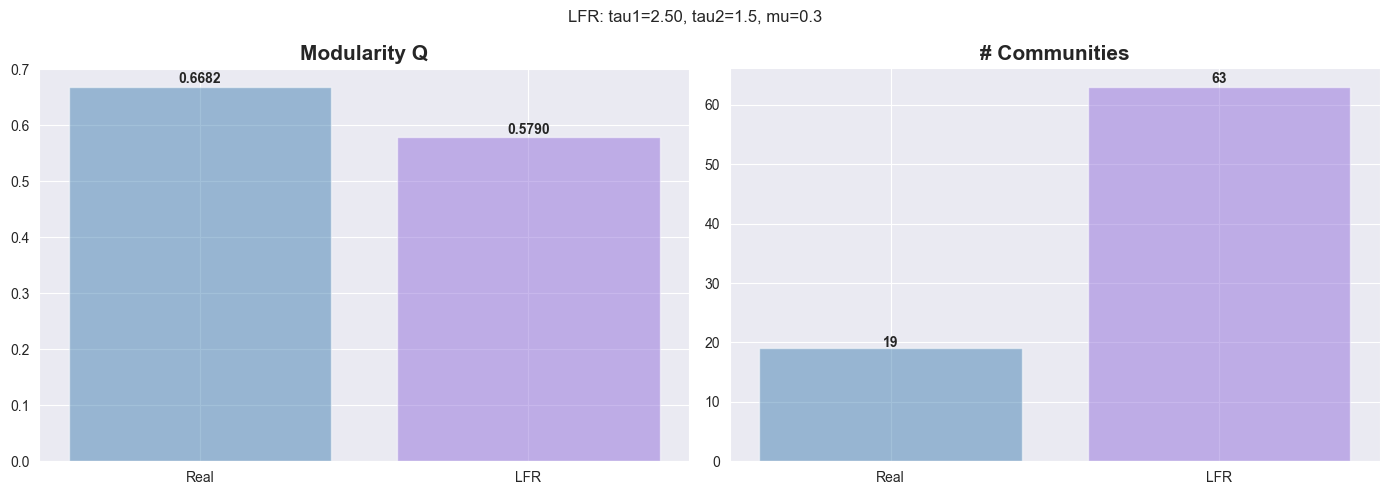

Metric                       Real        LFR
--------------------------------------------
Modularity                 0.6682     0.5790
Num communities                19         63


In [27]:
try:
    LFR = nx.generators.community.LFR_benchmark_graph(
        n=N,
        tau1=tau1,
        tau2=tau2,
        mu=mu,
        average_degree=int(avg_k),
        min_community=min_comm,
        max_degree=int(N**0.5),
        seed=42,
        max_iters=10000,
    )
    lfr_communities = {frozenset(LFR.nodes[v]['community']) for v in LFR}
    lfr_mod = nx.community.modularity(LFR, lfr_communities)

    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, vals, title in [
        (axes[0], [modularity, lfr_mod], 'Modularity Q'),
        (axes[1], [len(communities), len(lfr_communities)], '# Communities')
    ]:
        ax.bar(['Real', 'LFR'], vals, color=['steelblue', 'mediumpurple'], alpha=0.5)
        ax.set_title(title)
        for i, v in enumerate(vals):
            ax.text(i, v * 1.01, f'{v:.4f}' if isinstance(v, float) else str(v),
                    ha='center', fontweight='bold')
    plt.suptitle(f'LFR: tau1={tau1:.2f}, tau2={tau2}, mu={mu}', fontsize=12)
    plt.tight_layout()
    plt.show()

    print(f'{"Metric":<22} {"Real":>10} {"LFR":>10}')
    print('-' * 44)
    print(f'{"Modularity":<22} {modularity:>10.4f} {lfr_mod:>10.4f}')
    print(f'{"Num communities":<22} {len(communities):>10} {len(lfr_communities):>10}')

except nx.ExceededMaxIterations:
    lfr_mod = None
    print('LFR did not converge. Try: increase max_iters, raise min_community, or adjust tau1/mu')

---
## 12. Model Comparison Summary

The table below summarizes all comparison metrics between the real flight network
and five ideal network models, using identical N and ⟨k⟩.

| Metric                              | Real     | Model    |
|-------------------------------------|----------|----------|
| ER — degree std (dist width)        | 24.2458  | 3.3441   |
| ER — KS D (degree dist)             | D=0.6407 | p=0.00e+00 |
| WS — clustering coefficient         | 0.4874   | 0.4993   |
| WS — average path length            | 4.1009   | 4.8106   |
| BA — power-law alpha                | 1.7387   | 2.8764   |
| XBS — assortativity r               | -0.0098  | -0.1828  |
| LFR — modularity Q                  | 0.6682   | 0.5790   |

### Erdős–Rényi — Degree Distribution
The degree standard deviation of the real network (24.25) is **7.3× larger** than ER (3.34).
The KS statistic D = 0.64 with p ≈ 0 confirms that the two distributions are
**significantly different** — this difference is not due to statistical noise.

ER produces a narrow Poisson distribution because each edge is formed independently
without preference, so no hubs can grow large. In contrast, the real flight network
has major hubs like Atlanta, Dubai, and London Heathrow with hundreds of connections,
which are impossible under an ER model with the same ⟨k⟩.

**Conclusion: ER is not an appropriate model for flight networks.**

### Watts–Strogatz — Small-World Property
The real clustering coefficient (0.4874) is nearly identical to WS (0.4993) — a ratio of 0.976,
showing that WS captures local clustering behavior very well. Airports within the same
region (e.g., Western Europe) are indeed highly interconnected, forming strong local clusters,
just as WS predicts.

However, the real average path length (4.10) is lower than WS (4.81) — a ratio of 0.853,
indicating the real network is **15% more efficient** than WS predicts. WS creates shortcuts
via random rewiring, whereas the real network has mega-hubs (ATL, DXB, LHR) that connect
hundreds of airports simultaneously — far more efficient than random shortcuts.

**Conclusion: WS is the best among the five models, capturing clustering accurately,
but still underestimating global efficiency driven by major hubs.**

### Barabási–Albert — Scaling Exponent
The real alpha (1.74) is far below the BA alpha (2.88) and the theoretical BA alpha (≈3.0).
Additionally, distribution comparison shows that lognormal fits the real network better
than power-law (R = -41.46, p ≈ 0).

Together, these findings indicate that **pure preferential attachment is not the correct mechanism**:
flight network growth is constrained by airport capacity, regulation, and geography —
constraints absent in the ideal BA model, resulting in a lighter tail than predicted.

**Conclusion: BA captures the intuition of "rich get richer", but produces hubs that are too dominant compared to reality.**

### Xulvi-Brunet-Sokolov — Assortativity
The real network has r = -0.0098 (nearly neutral), while XBS produces r = -0.1828 (moderately disassortative).
This means XBS predicts that hubs should strongly prefer connecting to small airports
and avoid other hubs — but reality is less extreme.

Major hubs do serve many small airports, but they are also strongly interconnected
(e.g., LHR–JFK, DXB–SIN), which pulls r closer to zero.

**Conclusion: Flight networks are more neutral than XBS predictions — hubs do not avoid each other as strongly as modeled.**

### LFR Benchmark — Modularity
The real modularity (0.6682) is higher than LFR (0.5790) — a difference of 0.0892.
This indicates that **community structure in flight networks is stronger than what LFR models**.

Real geographic clusters (Asia-Pacific, Europe, North America, Middle East) are highly cohesive,
with relatively fewer inter-regional connections — more isolated than what LFR with μ = 0.3 produces.

**Conclusion: LFR underestimates the strength of geographic community structure in real flight networks.**

### Final Conclusion
No single model perfectly replicates the flight network.

WS comes closest — capturing small-world properties well, though underestimating APL efficiency.
ER, BA, and XBS each fail on the very metrics that define them, while LFR produces weaker
community structures than observed in reality.

This confirms that flight networks are complex systems shaped simultaneously by geography,
regulation, economics, and airline competition dynamics — and cannot be reduced
to a single generative mechanism.

In [28]:
print('\n' + '=' * 62)
print('  MODEL COMPARISON SUMMARY')
print('=' * 62)
print(f'{"Metric":<35} {"Real":>12} {"Model":>12}')
print('-' * 62)
print(f'{"ER  — degree std (dist width)":<35} {real_deg.std():>12.4f} {er_deg.std():>12.4f}')
print(f'{"ER  — KS D (degree dist)":<35} {"D="+f"{ks_stat:.4f}":>12}   p={ks_p:.2e}')
print(f'{"WS  — clustering coeff":<35} {cc:>12.4f} {ws_cc:>12.4f}')
print(f'{"WS  — avg path length":<35} {apl:>12.4f} {ws_apl:>12.4f}')
print(f'{"BA  — power-law alpha":<35} {real_fit.power_law.alpha:>12.4f} {ba_fit.power_law.alpha:>12.4f}')
print(f'{"XBS — assortativity r":<35} {real_r:>12.4f} {xbs_r:>12.4f}')
if lfr_mod is not None:
    print(f'{"LFR — modularity Q":<35} {modularity:>12.4f} {lfr_mod:>12.4f}')
else:
    print(f'{"LFR — modularity Q":<35} {modularity:>12.4f} {"(LFR failed)":>12}')
print('=' * 62)


  MODEL COMPARISON SUMMARY
Metric                                      Real        Model
--------------------------------------------------------------
ER  — degree std (dist width)            24.2458       3.3441
ER  — KS D (degree dist)                D=0.6407   p=0.00e+00
WS  — clustering coeff                    0.4874       0.4993
WS  — avg path length                     4.1009       4.8106
BA  — power-law alpha                     1.7387       2.8764
XBS — assortativity r                    -0.0098      -0.1828
LFR — modularity Q                        0.6682       0.5790
